### Multi-Layer Perceptron for Regression

The preprocessing for this task involved combining the two datasets, white and red wine. Then the target column, quality, was removed and turned into our y variable. 
The remaining features were then scaled using MinMaxScalar as it is better suited for neural networks. The dataset is then split into training and test sets we chose a 20/80 test/train split. MLP regression was then applied. 
We used a forward passing MLP an the parameters used, and provided the best results were random_state=1, hidden_layer_sizes=100, alpha=0.001, learning_rate_init=0.01, activation="tanh", early_stopping=True, max_iter=500.

MLP R2: 0.27

K-Fold Cross Validation was used to evaluate model performance with mean squared error as the evaluation metric, where mse is the mean +- the standard deviation acros the folds. The initial value for K=5. MSE scores per fold: [0.52953879 0.53779222 0.56512489 0.50062776 0.58472341]
Average MSE and standard deviation: (0.544 +- 0.029)


MLP R2: 0.27

MSE scores per fold: [0.52953879 0.53779222 0.56512489 0.50062776 0.58472341]
Average MSE and standard deviation: (0.544 +- 0.029)


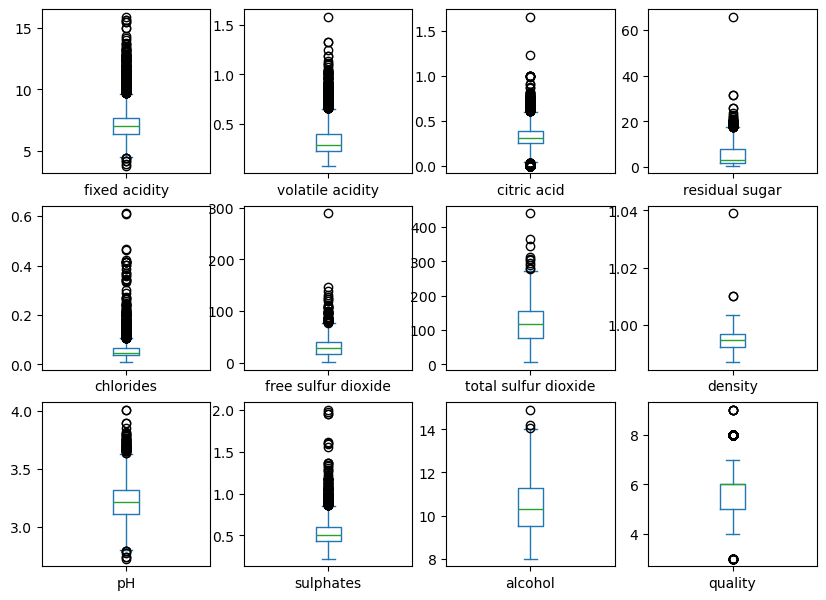

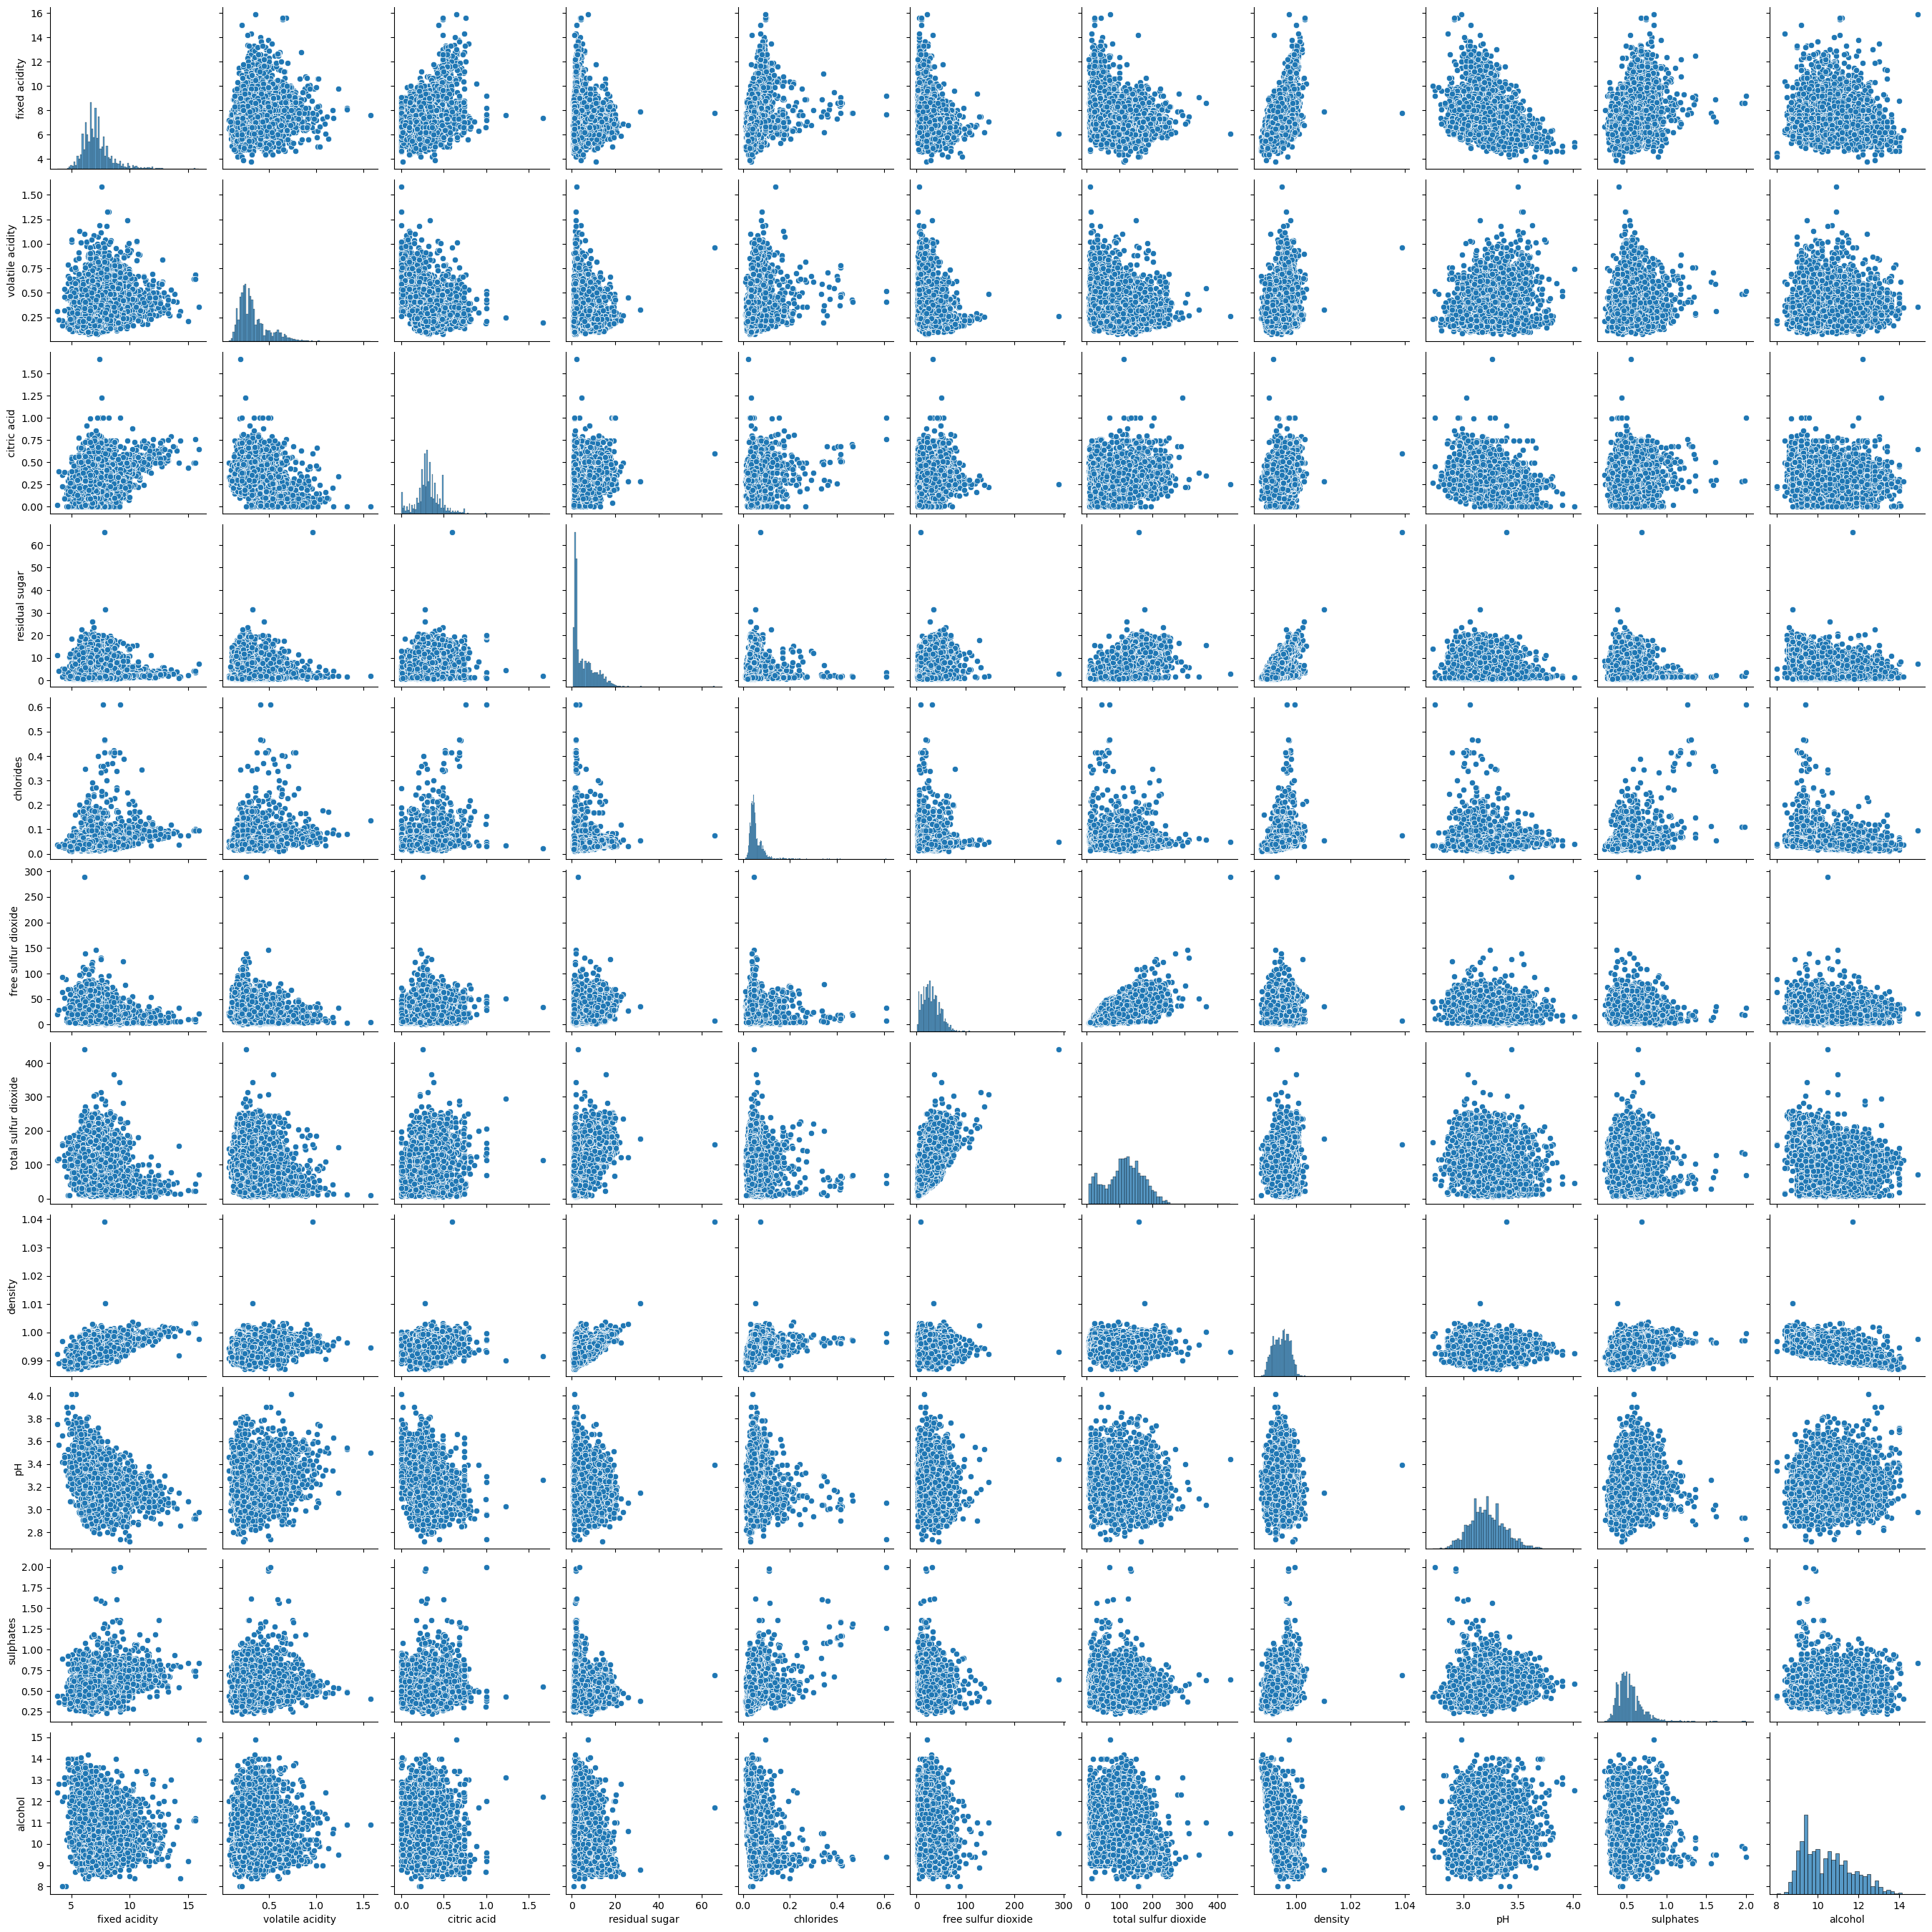

In [5]:
#Regression Task 
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import ColumnTransformer

from sklearn.model_selection import train_test_split

from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import KFold, cross_val_score


#read datasets
red_df=pd.read_csv('winequality-red.csv', index_col=False, sep= ";")
white_df=pd.read_csv('winequality-white.csv', index_col=False, sep=";")
#combine datasets
all_df = pd.concat([red_df, white_df], ignore_index = True)
all_df.head() 

#there are outliers in this dataset, use boxplots to find outliers
data_mean = all_df.iloc[:,:]
data_mean.plot(kind='box',subplots=True,layout=(8,4),sharex=False,sharey=False,fontsize=10,figsize=(10,20));

#visualise first 11 features with pairplot
sns.pairplot(all_df[list(all_df.columns[:11])])

#we are predicting quality, so make quality into y
y = all_df["quality"]
X = all_df.drop(columns="quality")

num_col = X.select_dtypes("number").columns

norm_x = ColumnTransformer([("num",MinMaxScaler(), num_col)])
scale_X = norm_x.fit_transform(X)

#create training and test datasets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

X_train = norm_x.fit_transform(X_train)
X_test = norm_x.transform(X_test)

#implement MLP
mlp_reg = MLPRegressor(random_state=1, hidden_layer_sizes=100, alpha=0.001, learning_rate_init=0.01, activation="tanh", early_stopping=True, max_iter=500).fit(X_train, y_train)
print('MLP R2: {:03.2f}'.format(mlp_reg.score(X_test, y_test)))

#apply k-fold cross val
cv = KFold(n_splits=5, shuffle=True, random_state=1) #start w k=5

scores_reg = cross_val_score(mlp_reg, scale_X , y, cv=cv, scoring="neg_mean_squared_error")
mse_scores = -scores_reg

print("\nMSE scores per fold:", mse_scores)
avg = (np.mean(mse_scores), np.std(mse_scores))

print("Average MSE and standard deviation: (%.3f +- %.3f)" % avg)



Numerical features: ['Age']
Categorical features: ['Gender', 'Polyuria', 'Polydipsia', 'sudden weight loss', 'weakness', 'Polyphagia', 'Genital thrush', 'visual blurring', 'Itching', 'Irritability', 'delayed healing', 'partial paresis', 'muscle stiffness', 'Alopecia', 'Obesity']
Target classes ['Positive' 'Negative']


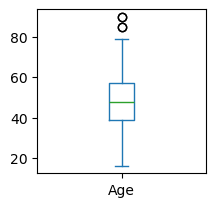

In [11]:
#Classification Task
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

import matplotlib.pyplot as plt

from sklearn import datasets, linear_model
from sklearn import preprocessing
from sklearn.preprocessing import LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder

from sklearn.model_selection import train_test_split

from sklearn.neural_network import MLPRegressor, MLPClassifier

#read dataset
diabetes_df = pd.read_csv('diabetes_data_upload.csv',index_col=False)

#there are outliers in this dataset, use boxplots to find outliers
data_mean = diabetes_df.iloc[:,:]
data_mean.plot(kind='box',subplots=True,layout=(8,4),sharex=False,sharey=False,fontsize=10,figsize=(10,20));

#we are predicting class so can drop class col and make into y
y = LabelEncoder().fit_transform(diabetes_df["class"])
X = diabetes_df.drop(columns=["class"])

#separate column types into number and category
num_col = X.select_dtypes(include="number").columns
cat_col = X.select_dtypes(exclude="number").columns

pro_diabetes_df = ColumnTransformer([("num",MinMaxScaler(), num_col), ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"),cat_col)])

print("Numerical features:", list(num_col))
print("Categorical features:", list(cat_col))
print("Target classes", diabetes_df["class"].unique())





In [12]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
# creates the MLP classification model
mlp_diabetes = Pipeline([("preprocessing", pro_diabetes_df), ("classifier", MLPClassifier(hidden_layer_sizes=(10,), activation="relu", solver="adam", max_iter=1000,
random_state=42))])
# Use 5-fold cross-validation for classification
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# Evaluate classification accuracy
scores = cross_val_score(
mlp_diabetes, X, y,cv=kfold, scoring="accuracy"
)
print("Accuracy for each fold:", scores)
print("Mean accuracy:", scores.mean())
print("Standard deviation:", scores.std())


Accuracy for each fold: [0.94230769 0.93269231 0.97115385 0.98076923 0.94230769]
Mean accuracy: 0.9538461538461538
Standard deviation: 0.018644922528524326


/opt/anaconda3/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


In [13]:
hidden_layers = [(5,), (10,), (20,), (10, 10)]

for layers in hidden_layers:
    mlp_model = Pipeline([("preprocessing", pro_diabetes_df), ("classifier", MLPClassifier(hidden_layer_sizes=layers, activation="relu", solver="adam", max_iter=1000, random_state=42))])

    scores = cross_val_score(mlp_model, X, y, cv=kfold, scoring="accuracy")

    print("Hidden layers:", layers)
    print("Mean accuracy: {:.2f}%".format(scores.mean() * 100))
    print("Standard deviation: {:.2f}%".format(scores.std() * 100))
    print() 

Hidden layers: (5,)
Mean accuracy: 93.08%
Standard deviation: 1.12%



/opt/anaconda3/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


Hidden layers: (10,)
Mean accuracy: 95.38%
Standard deviation: 1.86%

Hidden layers: (20,)
Mean accuracy: 96.35%
Standard deviation: 1.12%

Hidden layers: (10, 10)
Mean accuracy: 95.96%
Standard deviation: 0.94%



In [14]:

from sklearn.metrics import confusion_matrix, classification_report

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

mlp_final = Pipeline([("preprocessing", pro_diabetes_df), ("classifier", MLPClassifier(hidden_layer_sizes=(20,), activation="relu", solver="adam", max_iter=2000, random_state=42))])
mlp_final.fit(X_train, y_train)
y_pred = mlp_final.predict(X_test)

print("Test accuracy:", mlp_final.score(X_test,y_test))
print("Confusion matrix")
print(confusion_matrix(y_test, y_pred))

print("Classificarion report:")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

Test accuracy: 0.9743589743589743
Confusion matrix
[[59  1]
 [ 3 93]]
Classificarion report:
              precision    recall  f1-score   support

    Negative       0.95      0.98      0.97        60
    Positive       0.99      0.97      0.98        96

    accuracy                           0.97       156
   macro avg       0.97      0.98      0.97       156
weighted avg       0.97      0.97      0.97       156



In [15]:

final_cv_scores = cross_val_score(mlp_final, X, y, cv=kfold, scoring="accuracy")
print("Final fold accuracies:", final_cv_scores)
print("Final mean accuracy: {:.2f}%".format(final_cv_scores.mean() * 100))
print("Final standard deviation: {:.2f}%".format(final_cv_scores.std() * 100))

Final fold accuracies: [0.95192308 0.97115385 0.96153846 0.98076923 0.95192308]
Final mean accuracy: 96.35%
Final standard deviation: 1.12%
